# EDA LogHub: BGL, Windows, HealthApp, Apache

Исследование по 11 шагам: от происхождения и физического файла до разметки и временных окон.
Каждый раздел сопоставляет все четыре датасета. **Физическая строка, логическая запись и сообщение — разные единицы.**
Запись начинается с распознанного заголовка; строки без заголовка сохраняются вместе с предыдущей записью
и считаются кандидатами в продолжения, а не автоматически корректными многострочными сообщениями.

Полный поток используется для аудита строк, временных меток, объёмов, категорий и разметки.
При ограниченной памяти текст BGL и Windows изучается на равномерной выборке до 100 000 **целых записей**
(reservoir sampling, seed=42); Apache и HealthApp — полностью. Первые и 100 случайных **физических строк**
показываются независимо. Все оценки редкости, дублей текста, сущностей и сроков жизни шаблонов BGL/Windows
относятся к выборке: отсутствие в ней не означает отсутствия в полном файле.

Первый запуск читает около 29 ГБ и может занять десятки минут; повторный использует локальный кэш
`data/processed` с проверкой размера, mtime, версии аудита, размера выборки и seed.
Кэш можно пересоздать, передав `use_cache=False`. Сырые логи и кэш в Git не включаются.
Установка зависимостей: `python -m pip install -r requirements.txt`. Запуск — из корня проекта или `notebooks`.

In [1]:
import sys
from pathlib import Path
from collections import Counter
import html
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from IPython.display import display, HTML, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util/loghub.py").exists())
sys.path.insert(0, str(ROOT))
if (ROOT / "data/dependencies").exists():
    sys.path.append(str(ROOT / "data/dependencies"))
from util.loghub_eda import (
    audit_dataset, minute_series, window_counts, entities, mine_templates,
    template_lifetimes, text_profile, categorical_drift, gap_table, anomaly_episodes,
    ENTITY_PATTERNS,
    exact_bgl_duplicates,
)

SEED = 42
SAMPLE_SIZES = {"BGL": 100_000, "Windows": 100_000, "HealthApp": 300_000, "Apache": 100_000}
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 130)
pd.set_option("display.max_rows", 25)
plt.rcParams["figure.dpi"] = 100

def title(text):
    display(Markdown("### " + text))

def show_counter(counter, limit=10):
    series = pd.Series(counter, dtype="int64").sort_values(ascending=False)
    if series.empty:
        display(Markdown("Поле отсутствует или сущности не найдены."))
    else:
        display(pd.DataFrame({"count": series, "share": series / series.sum()}).head(limit))

def raw_details(label, rows):
    table = pd.DataFrame(rows, columns=["physical_line", "raw_text"])
    table["raw_text"] = table.raw_text.map(repr)
    with pd.option_context("display.max_colwidth", None):
        body = table.to_html(index=False, escape=True, max_rows=None)
    display(HTML(f"<details><summary>{html.escape(label)} ({len(rows)} строк)</summary>{body}</details>"))

audits = {name: audit_dataset(name, sample_size=size, seed=SEED) for name, size in SAMPLE_SIZES.items()}
datasets = {name: audit["sample"] for name, audit in audits.items()}
for name, audit in audits.items():
    counts, sample = audit["counts"], audit["sample"]
    assert counts["physical_lines"] == counts["records"] + counts.get("headerless_lines", 0), name
    assert sum(audit["minutes"].values()) == counts["records"] - counts.get("invalid_timestamp_records", 0), name
    assert len(sample) == min(SAMPLE_SIZES[name], counts["records"]), name
    assert sample.line_no.is_unique and sample.line_no.is_monotonic_increasing, name
    assert len(audit["first"]) == len(audit["raw_sample"]) == min(100, counts["physical_lines"]), name
display(pd.DataFrame([
    {"dataset": name, "full_records": a["counts"]["records"], "text_records": len(a["sample"]),
     "text_coverage": len(a["sample"]) / a["counts"]["records"]}
    for name, a in audits.items()
]))

,dataset,full_records,text_records,text_coverage
0,BGL,4747963,100000,0.021062
1,Windows,114422303,100000,0.000874
2,HealthApp,253395,253395,1.000000
3,Apache,52004,52004,1.000000


## 1. Происхождение данных

Архивы загружает Python-функция `ensure_dataset`, вызываемая из `audit_dataset`, из
[Zenodo, запись 3227177](https://zenodo.org/records/3227177). Это полные `.log` из архивов, а не демонстрационные 2k-выборки.
Условия исследовательского использования и цитирования приведены в [LogHub](https://github.com/logpai/loghub).
Авторы коллекции стараются сохранять исходные данные; это не гарантирует отсутствие фильтрации у каждого источника.
История всех фильтров/потерь, настройки ротации и полнота исходного сбора для этих файлов не задокументированы.

| Данные | Сервис и условия сбора | Что известно / чего не хватает |
|---|---|---|
| [BGL](https://github.com/logpai/loghub/blob/master/BGL/README.md) | BlueGene/L в LLNL; 131 072 процессора; системные RAS/приложения | Alert-категории в первом поле. Конкретные нагрузки и полнота журналирования неизвестны. |
| [Windows](https://github.com/logpai/loghub/blob/master/Windows/README.md) | Windows 7, лабораторный компьютер; объединены журналы `C:\Windows\Logs\CBS` | CBS обслуживает компоненты и обновления; конкатенация файлов может нарушать хронологию. Авторы указывают 226+ дней; ниже проверяем фактический диапазон. |
| [HealthApp](https://github.com/logpai/loghub/blob/master/HealthApp/README.md) | Android-приложение, один смартфон после 10+ дней использования | Устройство/часовой пояс, настройки логирования и действия пользователя не раскрыты. |
| [Apache](https://github.com/logpai/loghub/blob/master/Apache/README.md) | Error log HTTP-сервера на Linux | Это журнал ошибок, не access log: число строк нельзя интерпретировать как число HTTP-запросов. Нагрузка/конфигурация неизвестны. |

Диапазон ниже — минимум и максимум разобранных меток полного файла, а не доказательство непрерывного наблюдения.

In [2]:
display(pd.DataFrame([
    {"dataset": name, "observed_min": a["min_time"], "observed_max": a["max_time"],
     "span_days": (a["max_time"] - a["min_time"]).total_seconds() / 86400}
    for name, a in audits.items()
]))

,dataset,observed_min,observed_max,span_days
0,BGL,2005-06-03 15:42:50.363779,2006-01-04 08:00:05.233639,214.678644
1,Windows,2014-03-12 20:34:42.000000,2017-05-12 21:24:37.000000,1157.034664
2,HealthApp,2017-12-23 22:15:29.606000,2018-01-03 09:59:00.095000,10.488547
3,Apache,2005-06-09 06:07:04.000000,2006-02-28 03:49:01.000000,263.904132


## 2. Физическая организация файла

Архив — `tar.gz`; внутри текстовый `.log`. Разделители: BGL — пробелы и первые девять полей;
Windows — `datetime, level component message`; HealthApp — первые три `|` (дальнейшие `|` остаются в сообщении);
Apache — `[datetime] [level] message`. Аудит проверяет UTF-8 **по всему файлу**, отдельно считает BOM,
невалидные последовательности, символы замены и NUL. Отсутствие ошибок UTF-8 означает совместимость с этой
кодировкой, но не доказывает историческую кодировку ASCII-совместимого текста.
Средняя длина физической строки ниже дана в символах без CR/LF; размер файла — в байтах.

In [3]:
physical = []
for name, a in audits.items():
    c = a["counts"]
    physical.append({"dataset": name, "file_bytes": a["size_bytes"], "archive_bytes": a["archive_bytes"],
                     "GiB": a["size_bytes"] / 2**30, "physical_lines": c["physical_lines"],
                     "mean_line_chars": c["characters"] / c["physical_lines"],
                     **{key: c.get(key, 0) for key in ["LF", "CRLF", "no_final_newline", "UTF8_BOM", "invalid_utf8_lines", "replacement_char_lines", "NUL_lines"]}})
display(pd.DataFrame(physical).set_index("dataset"))
display(pd.DataFrame({n: a["sha256"] for n, a in audits.items()}, index=["SHA256 full raw file"]).T)

,file_bytes,archive_bytes,GiB,physical_lines,mean_line_chars,LF,CRLF,no_final_newline,UTF8_BOM,invalid_utf8_lines,replacement_char_lines,NUL_lines
dataset,,,,,,,,,,,,
BGL,743185031,62936967,0.692145,4747963,155.527115,4747963,0,0,0,0,0,4
Windows,28012696901,1670098945,26.088857,114608388,242.421001,0,114608388,0,1,0,0,0
HealthApp,23529930,2296618,0.021914,253395,90.858699,0,253395,0,0,0,0,1
Apache,5135876,262905,0.004783,56482,89.929447,56481,0,1,0,0,0,0


,SHA256 full raw file
BGL,666130b15ef44eb32fd02bd053e6c6e007c37696b5e7e8b9d8e45b729876a5d2
Windows,642bc26096229518e5682872ad6f7d586883b3626ed49a47f53e689c398d220e
HealthApp,d9d76ad2fb8f34ebba9ceda27d4ec9577ad7d5a3ec711f3396680e41d3f0d29c
Apache,23e616a1ed529bab9b20b9bc345d37035061eee971d246102bcc4937e51a039b


## 3. Первично смотрим на файл

Раскрывающиеся таблицы содержат по 100 первых и 100 случайных исходных строк с номерами,
без усечения текста (`repr` делает управляющие символы видимыми). Следом — строки без распознанного
заголовка и записи, в которые они попали. BGL начинается с **метки**, а не времени;
это корректный формат. В Apache текст без времени может быть самостоятельным сообщением без заголовка:
склейка — техническая договорённость для сохранения текста, а не установленная семантика.

Отдельно считаем дубли записей и повторения сообщений в текстовой области. Для BGL дополнительно
проверяем точные байтовые дубли **по всему файлу**: его временные метки монотонны, поэтому достаточно
сравнивать записи внутри группы совпавшего времени. Повторяющееся сообщение с другим временем не является
дублем записи. Полная внешняя дедупликация 28 ГБ Windows здесь не выполняется.
Отсутствие финального LF само по себе не доказывает обрыв записи.

In [4]:
quality_rows = []
for name, a in audits.items():
    title(name)
    c, df = a["counts"], datasets[name]
    raw_details("Первые физические строки", a["first"])
    raw_details("Случайные физические строки, seed=43", a["raw_sample"])
    raw_details("Первые строки без распознанного заголовка", a["unusual"])
    display(df.loc[df.physical_line_count > 1, ["line_no", "physical_line_count", "message"]].head(5))
    record_fields = [key for key in df.columns if key not in
                     ["line_no", "timestamp", "normalized_timestamp", "is_anomaly"]]
    quality_rows.append({"dataset": name, "full_logical_records": c["records"],
                        "mean_raw_record_chars_full_without_CRLF": c["characters"] / c["records"] if not c.get("orphan_lines", 0) else np.nan,
                        "empty_physical": c.get("empty_lines", 0), "headerless": c.get("headerless_lines", 0),
                        "orphan": c.get("orphan_lines", 0), "bad_time": c.get("invalid_timestamp_records", 0),
                        "text_scope": len(df), "duplicate_records_sample": int(df.duplicated(record_fields).sum()),
                        "repeated_messages_sample": int(df.message.duplicated().sum()),
                        "mean_record_message_chars_sample": df.message.str.len().mean(),
                        "empty_messages_sample": int(df.message.eq("").sum())})
display(pd.DataFrame(quality_rows).set_index("dataset"))
display(Markdown(f"BGL: точных повторов физических записей сверх первого по полному файлу — {exact_bgl_duplicates(audits['BGL'])}."))

### BGL

physical_line,raw_text
1,'- 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.363779 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
2,'- 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.527847 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
3,'- 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.675872 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
4,'- 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.823719 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
5,'- 1117838570 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.50.982731 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
6,'- 1117838571 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.51.131467 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
7,'- 1117838571 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.51.293532 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
8,'- 1117838571 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.51.428563 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
9,'- 1117838571 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.51.601412 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
10,'- 1117838571 2005.06.03 R02-M1-N0-C:J12-U11 2005-06-03-15.42.51.749199 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'


physical_line,raw_text
56243,'- 1117977679 2005.06.05 R34-M1-N0-C:J06-U01 2005-06-05-06.21.19.154890 R34-M1-N0-C:J06-U01 RAS KERNEL INFO generating core.8038'
125524,'- 1118079316 2005.06.06 R02-M1-N0-C:J12-U11 2005-06-06-10.35.16.041589 R02-M1-N0-C:J12-U11 RAS KERNEL INFO instruction cache parity error corrected'
235368,'KERNDTLB 1118537299 2005.06.11 R30-M0-N9-C:J16-U01 2005-06-11-17.48.19.471611 R30-M0-N9-C:J16-U01 RAS KERNEL FATAL data TLB error interrupt'
258613,'KERNDTLB 1118540706 2005.06.11 R30-M0-N9-C:J16-U01 2005-06-11-18.45.06.384576 R30-M0-N9-C:J16-U01 RAS KERNEL FATAL data TLB error interrupt'
354251,'KERNDTLB 1118555242 2005.06.11 R30-M0-N9-C:J16-U01 2005-06-11-22.47.22.673285 R30-M0-N9-C:J16-U01 RAS KERNEL FATAL data TLB error interrupt'
355118,'KERNDTLB 1118555372 2005.06.11 R30-M0-N9-C:J16-U01 2005-06-11-22.49.32.214553 R30-M0-N9-C:J16-U01 RAS KERNEL FATAL data TLB error interrupt'
408063,'- 1118710170 2005.06.13 R03-M0-N5-C:J11-U01 2005-06-13-17.49.30.571951 R03-M0-N5-C:J11-U01 RAS KERNEL FATAL instruction address: 0x00004ed8'
420313,'- 1118732692 2005.06.14 R37-M0-N0-C:J16-U11 2005-06-14-00.04.52.535236 R37-M0-N0-C:J16-U11 RAS KERNEL INFO generating core.3756'
431927,'KERNSTOR 1118765231 2005.06.14 R00-M1-ND-C:J11-U01 2005-06-14-09.07.11.613031 R00-M1-ND-C:J11-U01 RAS KERNEL FATAL data storage interrupt'
437857,'KERNSTOR 1118765419 2005.06.14 R07-M0-NF-C:J14-U01 2005-06-14-09.10.19.802967 R07-M0-NF-C:J14-U01 RAS KERNEL FATAL data storage interrupt'


physical_line,raw_text


,line_no,physical_line_count,message


### Windows

... (12 outputs left out)

physical_line,raw_text
2658,'script not found or unable to stat'
2659,'script not found or unable to stat'
2660,'script not found or unable to stat'
2661,'script not found or unable to stat'
2662,'script not found or unable to stat'
2663,'script not found or unable to stat'
2664,'script not found or unable to stat'
2665,'script not found or unable to stat'
2666,'script not found or unable to stat'
2667,'script not found or unable to stat'


,line_no,physical_line_count,message
2656,2657,17,[client 63.119.14.138] Directory index forbidden by rule: /var/www/html/\nscript not found or unable to stat\nscript not found...
2658,2675,7,workerEnv.init() ok /etc/httpd/conf/workers2.properties\nscript not found or unable to stat\nscript not found or unable to sta...
10212,10235,6,[client 24.195.248.187] Directory index forbidden by rule: /var/www/html/\nscript not found or unable to stat\nscript not foun...
10215,10243,2,mod_jk child init 1 -2\nscript not found or unable to stat
10218,10247,5,mod_jk child workerEnv in error state 3\nscript not found or unable to stat\nscript not found or unable to stat\nscript not fo...


,full_logical_records,mean_raw_record_chars_full_without_CRLF,empty_physical,headerless,orphan,bad_time,text_scope,duplicate_records_sample,repeated_messages_sample,mean_record_message_chars_sample,empty_messages_sample
dataset,,,,,,,,,,,
BGL,4747963,155.527115,0,0,0,0,100000,0,64213,49.006860,712
Windows,114422303,242.815250,35016,186085,0,0,100000,1362,64732,192.945500,0
HealthApp,253395,90.858699,0,0,0,0,253395,416,98226,47.226319,0
Apache,52004,97.673160,0,4478,0,0,52004,22821,36921,62.498000,0


BGL: точных повторов физических записей сверх первого по полному файлу — 4.

## 4. Время

Внешние метки: BGL — микросекунды, Windows/Apache — секунды, HealthApp — миллисекунды.
Это точность записи формата, а не гарантия точности часов. Во внешних заголовках нет UTC offset;
таймзона неизвестна, поэтому время сохраняем naive и не совмещаем между системами.
У Windows внутри сообщения CSI встречается второе время: его нельзя автоматически подставлять вместо заголовка.
У BGL есть Unix timestamp, что позволяет измерить смещение к текстовому времени без догадки о часовом поясе.

**Исправление HealthApp:** дата без нулевого дополнения (`201811` = 2018-01-01), часы/минуты/секунды также
могут содержать одну цифру. Последнее поле — целые миллисекунды: `:1` = 1 мс, а не десятая доля секунды.
Возможные календарные разбиения проверяются; неоднозначные даты не угадываем.
В одном заголовке присутствует NUL-префикс: он отмечен аудитом и убран только для разбора заголовка.
**Исправление BGL:** пустое сообщение после девяти полей допустимо и больше не приводит к потере записи.

Первые/последние в файле и min/max хронологии различаем. Возвраты времени и соседние совпадения считаются
по полному потоку; все совпадения времён — дополнительно по текстовой выборке.
Пустые минуты и интервалы между ними не позволяют отличить простой от потери данных без внешнего мониторинга.

In [5]:
time_rows = []
for name, a in audits.items():
    df, c = datasets[name], a["counts"]
    time_rows.append({"dataset": name, "first_in_file": a["first_time"], "last_in_file": a["last_time"],
                      "min": a["min_time"], "max": a["max_time"],
                      "last_minus_first_file_days": (a["last_time"] - a["first_time"]).total_seconds() / 86400,
                      "max_minus_min_chronological_days": (a["max_time"] - a["min_time"]).total_seconds() / 86400,
                      "backward_steps_full": c.get("backward_steps", 0),
                      "adjacent_equal_full": c.get("adjacent_duplicate_timestamps", 0),
                      "all_equal_sample_excess": int(df.timestamp.dropna().duplicated().sum()),
                      "fractional_timestamp_share_sample": df.timestamp.dt.microsecond.ne(0).mean()})
    title(name + ": самые длинные интервалы без событий (полный файл)")
    display(gap_table(a))
display(pd.DataFrame(time_rows).set_index("dataset"))
windows_years = Counter()
for minute, number in audits["Windows"]["minutes"].items():
    windows_years[minute[:4]] += number
title("Windows: полный счётчик записей по году внешней временной метки")
show_counter(windows_years)
bgl = datasets["BGL"]
offset_hours = (bgl.timestamp - pd.to_datetime(bgl.unix_ts, unit="s")).dt.total_seconds().floordiv(3600)
show_counter(Counter(offset_hours), 10)
display(Markdown("BGL: распределение целочасового смещения текстового времени относительно Unix (по выборке). Дробная часть включает микросекунды."))

### BGL: самые длинные интервалы без событий (полный файл)

,previous_occupied_minute,next_occupied_minute,empty_minutes
7490,2005-07-31 12:10:00,2005-08-02 13:13:00,2942.0
24538,2005-12-04 16:52:00,2005-12-05 10:42:00,1069.0
7929,2005-08-03 17:19:00,2005-08-04 08:37:00,917.0
12934,2005-09-13 17:26:00,2005-09-14 08:13:00,886.0
26015,2005-12-16 19:13:00,2005-12-17 09:32:00,858.0
12176,2005-09-05 12:39:00,2005-09-06 02:54:00,854.0
7462,2005-07-29 22:15:00,2005-07-30 12:01:00,825.0
8441,2005-08-05 20:02:00,2005-08-06 09:33:00,810.0
15246,2005-10-05 15:20:00,2005-10-06 04:22:00,781.0
7459,2005-07-29 08:38:00,2005-07-29 21:18:00,759.0


### Windows: самые длинные интервалы без событий (полный файл)

,previous_occupied_minute,next_occupied_minute,empty_minutes
106,2014-07-09 16:22:00,2015-01-16 11:09:00,274726.0
35,2014-03-12 21:32:00,2014-06-30 16:27:00,158094.0
169,2015-01-16 14:27:00,2015-04-08 10:46:00,117858.0
373,2015-04-21 10:20:00,2015-05-08 10:56:00,24515.0
367,2015-04-09 11:10:00,2015-04-21 10:09:00,17218.0
74,2014-07-02 17:22:00,2014-07-09 15:33:00,9970.0
5628,2017-04-24 20:45:00,2017-04-30 19:58:00,8592.0
38,2014-06-30 16:33:00,2014-07-02 10:46:00,2532.0
2359,2016-02-09 20:19:00,2016-02-11 12:00:00,2380.0
4378,2016-11-09 12:06:00,2016-11-10 13:55:00,1548.0


### HealthApp: самые длинные интервалы без событий (полный файл)

,previous_occupied_minute,next_occupied_minute,empty_minutes
1360,2017-12-26 02:22:00,2017-12-26 08:00:00,337.0
3643,2017-12-30 05:12:00,2017-12-30 07:11:00,118.0
4321,2017-12-31 04:42:00,2017-12-31 06:41:00,118.0
863,2017-12-25 05:10:00,2017-12-25 07:07:00,116.0
3009,2017-12-29 03:02:00,2017-12-29 04:58:00,115.0
304,2017-12-24 06:28:00,2017-12-24 08:21:00,112.0
861,2017-12-25 03:15:00,2017-12-25 05:08:00,112.0
2773,2017-12-28 15:44:00,2017-12-28 17:37:00,112.0
3010,2017-12-29 04:58:00,2017-12-29 06:50:00,111.0
4320,2017-12-31 03:04:00,2017-12-31 04:42:00,97.0


... (3 outputs left out)

### Windows: полный счётчик записей по году внешней временной метки

,count,share
2015,50831314,0.444243
2016,50525765,0.441573
2017,11380071,0.099457
2014,1685153,0.014727


,count,share
-7.0,77048,0.77048
-8.0,22952,0.22952


BGL: распределение целочасового смещения текстового времени относительно Unix (по выборке). Дробная часть включает микросекунды.

## 5. Объём и распределение

Полные количества записей агрегируем в минуты/часы/дни с явными нулевыми интервалами.
Крайние окна могут быть неполными. Распределение по часам суток нормируем на число соответствующих календарных
часовых окон; это описательная проверка цикличности, без доказательства сезонной модели.
Категории и их месячный дрейф вычисляются по полному файлу. TV distance лежит в [0,1];
первый/последний месяцы могут быть неполными, поэтому дрейф не равен инциденту.

BGL содержит узлы и подсистемы; Windows и HealthApp — компоненты одной системы/приложения.
Наличие компонентов не доказывает микросервисную архитектуру. В Apache, Windows и HealthApp
внешнего поля host нет: IP из сообщения не считаем хостом-продуцентом. У HealthApp нет поля уровня.

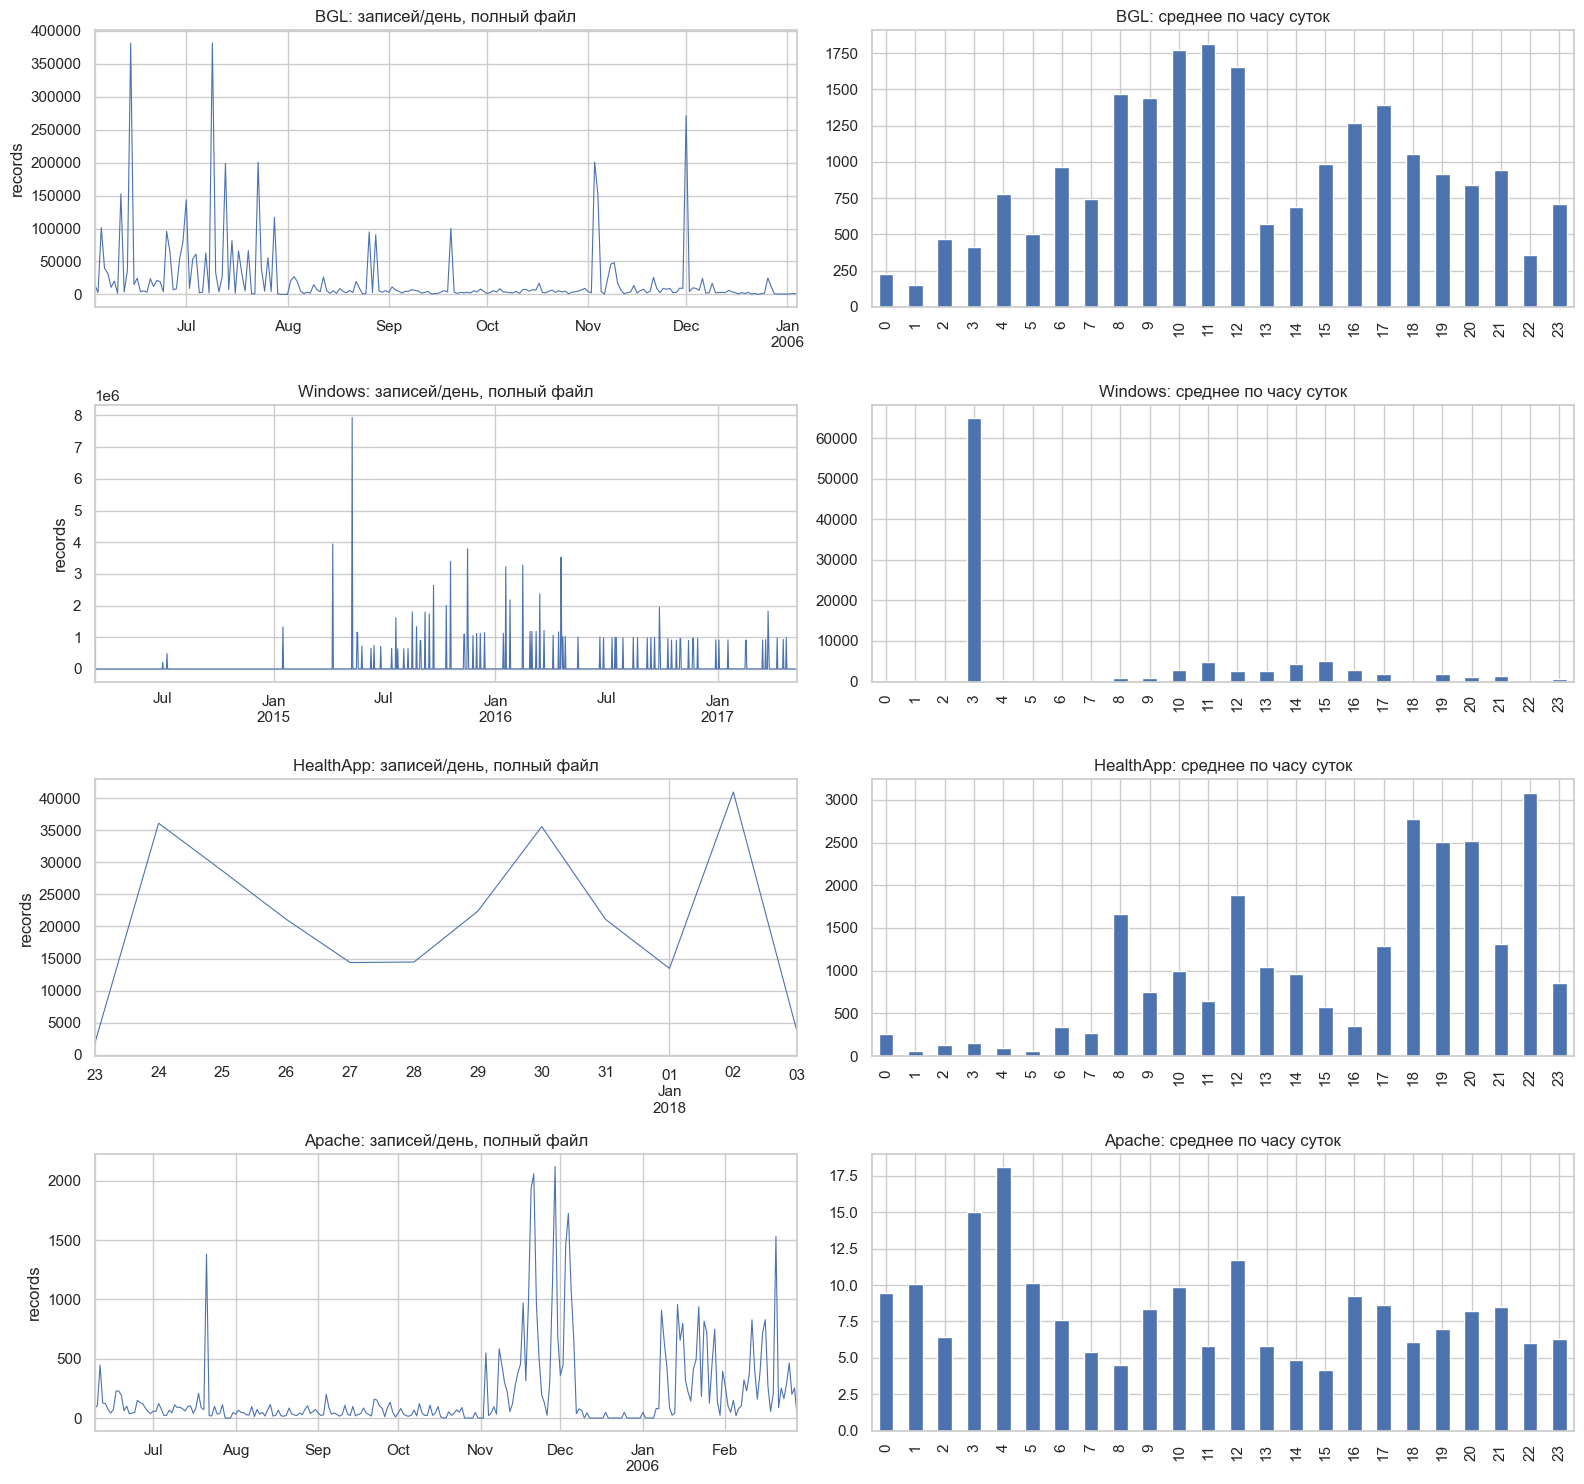

,dataset,window,mean,median,p99,max,zero_share
0,BGL,1min,15.358667,0.0,316.00,16409,0.910493
1,BGL,1h,921.219053,13.0,23755.84,160082,0.298021
2,BGL,1D,21981.310185,4932.5,260780.40,381827,0.004630
3,Windows,1min,68.675454,0.0,0.00,1048512,0.996577
4,Windows,1h,4120.356608,0.0,921.00,3786210,0.929924
5,Windows,1D,98810.278929,1009.0,1875722.96,7937376,0.362694
6,HealthApp,1min,16.775571,0.0,425.96,990,0.536776
7,HealthApp,1h,1005.535714,310.0,6495.47,9454,0.047619
8,HealthApp,1D,21116.250000,21094.5,40399.40,40934,0.000000
9,Apache,1min,0.136844,0.0,1.00,1286,0.978270


In [6]:
volume_rows = []
fig, axes = plt.subplots(4, 2, figsize=(16, 15))
for row, (name, a) in enumerate(audits.items()):
    for rule in ["1min", "1h", "1D"]:
        counts = window_counts(a, rule)
        volume_rows.append({"dataset": name, "window": rule, "mean": counts.mean(),
                            "median": counts.median(), "p99": counts.quantile(.99),
                            "max": counts.max(), "zero_share": counts.eq(0).mean()})
    daily, hourly = window_counts(a, "1D"), window_counts(a, "1h")
    daily.plot(ax=axes[row, 0], lw=.8, title=name + ": записей/день, полный файл")
    hourly.groupby(hourly.index.hour).mean().plot.bar(ax=axes[row, 1], title=name + ": среднее по часу суток")
    axes[row, 0].set_ylabel("records")
plt.tight_layout()
plt.show()
display(pd.DataFrame(volume_rows))

In [7]:
for name, a in audits.items():
    for field, counter_key in [("level", "levels"), ("component", "components"), ("host", "hosts")]:
        title(name + " / " + field + ": полный файл")
        show_counter(a[counter_key])
        drift = categorical_drift(a, field)
        if not drift.empty:
            display(drift)

### BGL / level: полный файл

,count,share
INFO,3735813,7.868244e-01
FATAL,855195,1.801183e-01
ERROR,112355,2.366383e-02
WARNING,23357,4.919373e-03
SEVERE,19213,4.046577e-03
FAILURE,1714,3.609969e-04
Kill,306,6.444869e-05
single,4,8.424665e-07
microseconds,4,8.424665e-07
"0x00544eb8,",2,4.212333e-07


,events,TV_to_previous_month,largest_category,largest_share
month,,,,
2005-06,1240932.0,NaN,INFO,0.552075
2005-07,1667866.0,0.865725,INFO,0.984860
2005-08,403715.0,0.603409,INFO,0.683155
2005-09,219277.0,0.858351,FATAL,0.373126
2005-10,153351.0,0.831904,INFO,0.698215
2005-11,638208.0,0.446414,INFO,0.918812
2005-12,421645.0,0.066124,INFO,0.888382
2006-01,2969.0,0.218203,INFO,0.784439


### BGL / component: полный файл

,count,share
RAS/KERNEL,4324651,0.910843
RAS/APP,228536,0.048133
NULL/DISCOVERY,97172,0.020466
RAS/MMCS,88930,0.018730
NULL/HARDWARE,5148,0.001084
NULL/MONITOR,1681,0.000354
RAS/LINKCARD,1170,0.000246
KERNEL/FATAL,306,0.000064
NULL/CMCS,211,0.000044
RAS/BGLMASTER,145,0.000031


,events,TV_to_previous_month,largest_category,largest_share
month,,,,
2005-06,1240932.0,NaN,RAS/KERNEL,0.983028
2005-07,1667866.0,0.014917,RAS/KERNEL,0.989594
2005-08,403715.0,0.620859,RAS/KERNEL,0.679445
2005-09,219277.0,0.774271,RAS/KERNEL,0.373240
2005-10,153351.0,0.721816,RAS/KERNEL,0.733820
2005-11,638208.0,0.419272,RAS/KERNEL,0.940830
2005-12,421645.0,0.073819,RAS/KERNEL,0.906787
2006-01,2969.0,0.077162,RAS/KERNEL,0.945099


... (21 outputs left out)

### Apache / component: полный файл

Поле отсутствует или сущности не найдены.

### Apache / host: полный файл

Поле отсутствует или сущности не найдены.

## 6. Сообщения

Текстовая область: полные Apache/HealthApp, равномерные выборки BGL/Windows.
Длины — число символов всего сообщения, включая сохранённые продолжения. Выбросы — выше Q3+1.5×IQR;
длинная строка или редкое слово сами по себе не являются аномалией. Слова — буквенные Unicode-последовательности,
приведённые к нижнему регистру, без стоп-слов; биграммы не переходят через границу сообщения.
«Пунктуация/символы» включает небуквенные и нецифровые непробельные символы.
Отдельно считаем классы токенов после разбиения по пробельным символам: только цифры, только буквы,
только пунктуация либо смешанный состав (например, `code=123` или слово с запятой).
Упоминания компонентов ищем среди 20 самых частых **других** компонентов: это текстовые совпадения, не граф вызовов.

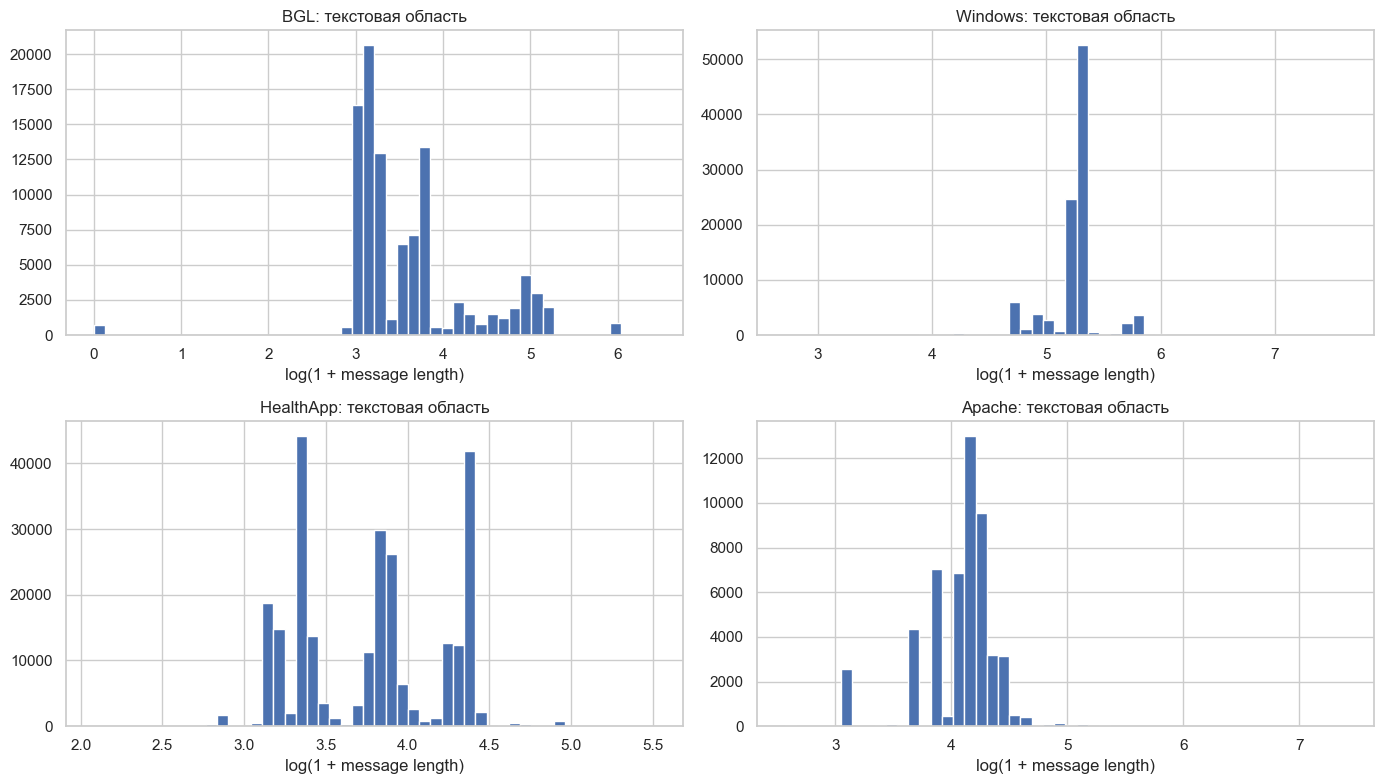

,dataset,scope_records,mean,median,p99,max,IQR_upper,above_IQR
0,BGL,100000,49.006860,26.0,180.0,616,81.0,15198
1,Windows,100000,192.945500,193.0,330.0,2045,220.5,6741
2,HealthApp,253395,47.226319,44.0,82.0,247,125.5,874
3,Apache,52004,62.498000,63.0,133.0,1638,104.0,761


### BGL: самые длинные сообщения

,line_no,timestamp,message
61278,2912906,2005-08-02 16:43:47.460139,While initializing node card iDo machine with LP of FF:F2:9F:16:DE:6A:00:0D:60:E9:21:95 caught java.io.IOException: Could not ...
61279,2912910,2005-08-02 16:43:47.555183,While initializing node card iDo machine with LP of FF:F2:9F:16:DA:F6:00:0D:60:E9:25:09 caught java.io.IOException: Could not ...
72865,3465104,2005-09-20 12:28:27.078199,While initializing link card iDo machine with LP of FF:F2:9F:15:7D:2A:00:0D:60:EA:82:D5 caught java.io.IOException: Could not ...
72866,3465114,2005-09-20 12:28:28.165966,While initializing link card iDo machine with LP of FF:F2:9F:15:7D:45:00:0D:60:EA:82:BA caught java.io.IOException: Could not ...
72867,3465119,2005-09-20 12:28:31.555884,While initializing node card iDo machine with LP of FF:F2:9F:16:DE:10:00:0D:60:E9:21:EF caught java.io.IOException: Could not ...


### BGL: целостные сообщения

,occurrences
message,
data TLB error interrupt,3265
0 microseconds spent in the rbs signal handler during 0 calls. 0 microseconds was the maximum time for a single instance of a correctable ddr.,2861
instruction cache parity error corrected,2220
"idoproxydb hit ASSERT condition: ASSERT expression=0 Source file=idotransportmgr.cpp Source line=1043 Function=int IdoTransportMgr::SendPacket(IdoUdpMgr*, BglCtlPavTrace*)",1779
1146800 double-hummer alignment exceptions,1496
8 floating point alignment exceptions,1382
data storage interrupt,1348
5 floating point alignment exceptions,1087
instruction address: 0x00004ed8,975


,unique_messages,singletons,messages_with_2_to_5_occurrences
0,35787,24745,9904


... (65 outputs left out)

### Apache: character_classes

,count,share
letter,2130402,0.655479
punctuation_or_symbol,405010,0.124613
digit,378942,0.116592
space,335792,0.103316


### Apache: token_classes

,count,share
letters,213633,0.550929
mixed,153946,0.397004
number,19840,0.051164
punctuation,350,0.000903


In [8]:
text_summaries = []
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (name, df) in zip(axes.flat, datasets.items()):
    lengths = df.message.str.len()
    q1, q3 = lengths.quantile([.25, .75])
    cutoff = q3 + 1.5 * (q3 - q1)
    text_summaries.append({"dataset": name, "scope_records": len(df), "mean": lengths.mean(),
                           "median": lengths.median(), "p99": lengths.quantile(.99), "max": lengths.max(),
                           "IQR_upper": cutoff, "above_IQR": int(lengths.gt(cutoff).sum())})
    ax.hist(np.log1p(lengths), bins=50)
    ax.set_title(name + ": текстовая область")
    ax.set_xlabel("log(1 + message length)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(text_summaries))
for name, df in datasets.items():
    title(name + ": самые длинные сообщения")
    display(df.loc[df.message.str.len().nlargest(5).index, ["line_no", "timestamp", "message"]])
    counts = df.message.value_counts()
    title(name + ": целостные сообщения")
    display(counts.head(10).rename("occurrences").to_frame())
    display(pd.DataFrame({"unique_messages": [len(counts)], "singletons": [counts.eq(1).sum()],
                          "messages_with_2_to_5_occurrences": [counts.between(2, 5).sum()]}))
    display(counts[counts.eq(1)].head(10).rename("singleton_examples").to_frame())
    display(counts[counts.between(2, 5)].head(10).rename("less_rare_examples").to_frame())
    words, bigrams, classes, token_classes = text_profile(df.message)
    for label, counter in [("words", words), ("bigrams", bigrams), ("character_classes", classes), ("token_classes", token_classes)]:
        title(name + ": " + label)
        show_counter(counter)
        if label in ("words", "bigrams"):
            display(pd.Series(dict(sorted(counter.items(), key=lambda item: (item[1], item[0]))[:10]),
                              name="least_frequent").to_frame())
    if "component" in df:
        mentions = []
        for target in df.component.value_counts().head(20).index:
            mask = df.component.ne(target) & df.message.str.contains(r"(?<!\w)" + re.escape(target) + r"(?!\w)", regex=True)
            for source, count in df.loc[mask, "component"].value_counts().items():
                mentions.append({"producer": source, "mentioned": target, "records": count})
        title(name + ": упоминания других компонентов")
        display(pd.DataFrame(mentions).sort_values("records", ascending=False).head(15) if mentions else "Не найдены среди top-20 компонентов")

## 7. Entity recognition

Регулярные выражения выделяют IPv4, IPv6, явные порты и IP:port, UUID, кандидаты в идентификаторы устройств,
пути Windows/POSIX, URL, кандидаты в хэши и идентификаторы сессии. IP и диапазон портов валидируются;
хэш по длине/алфавиту может оказаться иным идентификатором. Вложенные классы могут пересекаться.
Одна сущность, повторённая несколько раз в сообщении, увеличивает число упоминаний несколько раз.
Счётчики ниже относятся к текстовой области, а не ко всему Windows/BGL.

Session/thread/device ID не взаимозаменяемы. Ищем явные `session`, `correlation`, `activity` поля и
проверяем повторяемость кандидатов; для Windows дополнительно показываем реальные сообщения с Session.
Учтены поля с пробелом (`session id`); кандидат должен содержать цифру, чтобы отсечь наблюдавшиеся
слова `package` и `mutexes`. Это эвристика данного исследования: полностью буквенные session ID она не находит.
Результат не доказывает границы транзакций без документации приложения.

In [9]:
entity_results = {}
entity_rows = []
for name, df in datasets.items():
    entity_results[name] = entities(df.message)
    for kind, counter in entity_results[name].items():
        entity_rows.append({"dataset": name, "kind": kind, "unique": len(counter), "mentions": sum(counter.values())})
        if counter:
            title(name + " / " + kind)
            show_counter(counter, 5)
    sessions = entity_results[name]["session_candidate"]
    title(name + ": проверка кандидатов session ID")
    display(pd.DataFrame({"unique": [len(sessions)], "repeated_ids": [sum(n > 1 for n in sessions.values())]}))
    session_rows = []
    session_regex = re.compile(ENTITY_PATTERNS["session_candidate"])
    for timestamp, message in zip(df.timestamp, df.message):
        for match in session_regex.finditer(message):
            if any(char.isdigit() for char in match.group(1)):
                session_rows.append((match.group(1), timestamp))
    if session_rows:
        session_frame = pd.DataFrame(session_rows, columns=["candidate_id", "timestamp"])
        spans = session_frame.groupby("candidate_id").agg(mentions=("timestamp", "size"),
                                                         first_seen=("timestamp", "min"), last_seen=("timestamp", "max"))
        spans["span"] = spans.last_seen - spans.first_seen
        display(spans.sort_values("mentions", ascending=False).head(10))
    if "thread_id" in df:
        display(Markdown(f"Thread ID: {df.thread_id.nunique()} уникальных значений; это поле потока, не подтверждённый session ID."))
    display(df.loc[df.message.str.contains(r"(?i)session|correlation|activity", regex=True), ["timestamp", "message"]].head(5))
display(pd.DataFrame(entity_rows))

### BGL / IPv4

,count,share
172.16.96.116,1317,0.759516
0.0.0.0,4,0.002307
127.0.0.1,4,0.002307
10.0.0.105,3,0.001730
10.4.0.74,3,0.001730


### BGL / port_explicit

,count,share
0,20,0.014959
49980,2,0.001496
41007,2,0.001496
40375,2,0.001496
45822,2,0.001496


### BGL / device_id_candidate

,count,share
device required,19,0.103261
R27-M1-L3-U18-C,13,0.070652
R33-M1-L0-U22-C,8,0.043478
R06-M0-L0,4,0.021739
R21-M1-L3,4,0.021739


... (31 outputs left out)

### Apache: проверка кандидатов session ID

,unique,repeated_ids
0,0,0


,timestamp,message
15,2005-06-09 06:07:16,mod_python: Creating 32 session mutexes based on 150 max processes and 0 max threads.
133,2005-06-10 11:32:35,mod_python: Creating 32 session mutexes based on 150 max processes and 0 max threads.
686,2005-06-12 04:04:32,mod_python: Creating 32 session mutexes based on 150 max processes and 0 max threads.
1146,2005-06-17 04:03:45,mod_python: Creating 32 session mutexes based on 150 max processes and 0 max threads.
1572,2005-06-19 04:09:09,mod_python: Creating 32 session mutexes based on 150 max processes and 0 max threads.


,dataset,kind,unique,mentions
0,BGL,IPv4,383,1734
1,BGL,IPv6_candidate,0,0
2,BGL,port_explicit,1281,1337
3,BGL,UUID,0,0
4,BGL,device_id_candidate,109,184
...,...,...,...,...
31,Apache,device_id_candidate,0,0
32,Apache,path,111,36791
33,Apache,URL,0,0
34,Apache,hash_candidate,0,0


### Проверка смысла выделенных сущностей

В Windows найдено **368 session-кандидатов в 368 упоминаниях**: 367 значений вида `число_число` и `session id: 142859`. Все они встретились в выборке по одному разу; по такой выборке нельзя восстановить полные сессии. Для сессионной модели нужен отбор целых сессий или отдельный проход по полному потоку. Слова `package` в Windows и `mutexes` в Apache оказались частями фраз, а не session ID, и исключены.

У HealthApp единственный IPv4-кандидат — `1.0.0.0`, пять упоминаний в `MyServiceConn connect 1.0.0.0`. Синтаксическая валидность адреса не устанавливает его назначение. Аналогично, регулярное выражение для хэша, пути или устройства не заменяет проверку контекста.

## 8. Шаблоны

Используем [Drain3](https://github.com/logpai/Drain3): depth=4, sim_th=0.4, без удаления кластеров.
До обучения применяем явные маски URL/UUID/путей/IP/хэшей/узлов BGL, чисел и CSI-счётчиков;
порядок масок сохраняет целостность путей Windows. Каждая запись текстовой области поступает один раз
в порядке файла. Итоговый текст шаблона берём по стабильному cluster ID после завершения обучения:
ранние варианты шаблона не считаются отдельными событиями.
Числовые маски могут скрывать полезные статус-коды и коды ошибок: перед моделированием нужна ручная
проверка качества кластеров и уточнение масок для полей с фиксированным смыслом.

Показываем частые и редкие шаблоны, первое/последнее наблюдение и ежедневную активность пяти самых частых.
Ранняя последняя дата означает только отсутствие последующих **наблюдений**: в выборке нельзя доказать
исчезновение шаблона. Для supervised-модели парсер следует обучать только на train-периоде;
здесь обучение на всей текстовой области используется исключительно для описательного EDA.

### BGL: Drain3 (текстовая область)

,templates,singletons,top10_share
0,312,72,0.73387


,count,first_seen,last_seen,observed_span
template,,,,
generating core.<NUM>,36021,2005-06-03 15:51:25.712950,2005-07-28 13:10:51.789855,54 days 21:19:26.076905
iar <*> dear <*>,9300,2005-08-26 11:47:25.274555,2005-11-10 23:13:48.364569,76 days 11:26:23.090014
<NUM> floating point alignment exceptions,5478,2005-07-20 16:00:38.818746,2005-11-10 23:12:57.375076,113 days 07:12:18.556330
<NUM> double-hummer alignment exceptions,5372,2005-06-03 16:47:21.365393,2005-08-28 02:11:36.957838,85 days 09:24:15.592445
"CE sym <NUM>, at <HEX>, mask <HEX>",4209,2005-06-03 16:12:24.492830,2005-12-06 01:14:39.414887,185 days 09:02:14.922057
data TLB error interrupt,3265,2005-06-05 00:37:03.747646,2005-07-18 16:02:18.020229,43 days 15:25:14.272583
"<NUM> total interrupts. <NUM> critical input interrupts. <NUM> microseconds total spent on critical input interrupts, <NUM> microseconds max time in a critical input interrupt.",2878,2005-12-01 06:34:46.344173,2005-12-04 07:05:24.061786,3 days 00:30:37.717613
<NUM> microseconds spent in the rbs signal handler during <NUM> calls. <NUM> microseconds was the maximum time for a single instance of a correctable ddr.,2864,2005-12-01 06:34:45.810213,2005-12-04 07:05:22.764922,3 days 00:30:36.954709
instruction cache parity error corrected,2220,2005-06-03 15:43:01.470239,2005-12-31 01:54:31.864460,210 days 10:11:30.394221


,count,first_seen,last_seen,observed_span
template,,,,
<NUM>:0000000e <NUM>:000865b0 <NUM>:1fea7b68 <NUM>:<NUM>,1,2005-06-05 07:08:12.752279,2005-06-05 07:08:12.752279,0 days
<NUM>:<NUM> <NUM>:00089b10 <NUM>:00089b08 <NUM>:000887dc,1,2005-06-07 05:33:04.238597,2005-06-07 05:33:04.238597,0 days
<NUM>:0da3a530 <NUM>:059674c0 <NUM>:0dfc8338 <NUM>:0e110530,1,2005-06-13 02:23:39.936794,2005-06-13 02:23:39.936794,0 days
"PrepareForService is being done on this card(mLctn(<device_id_candidate>, mCardSernum(203231503833343000000000594c31304b34323830303232), mLp(FF:F2:9F:<NUM>:E9:D4:<NUM>:0D:<NUM>:E9:<NUM>:2B), mIp(<IPv4>), mType(<NUM>)) by root",1,2005-06-20 07:36:28.643263,2005-06-20 07:36:28.643263,0 days
BglIdoChip table has <NUM> IDOs with the same IP address (<IPv4>),1,2005-06-20 08:29:20.596122,2005-06-20 08:29:20.596122,0 days
"rror threshold, consider replacing the card",1,2005-06-26 10:10:11.683176,2005-06-26 10:10:11.683176,0 days
"ddr: Unable to steer rank=<NUM>, symbol=<NUM> - rank is already steering symbol <NUM>. Due to multiple symbols being over the correctable",1,2005-06-27 01:33:10.973164,2005-06-27 01:33:10.973164,0 days
"While initializing node card, ido with LP of FF:F2:9F:<NUM>:E8:1A:<NUM>:0D:<NUM>:E9:<NUM>:E5 caught java.lang.IllegalStateException: while executing I2C Operation caught java.lang.RuntimeException: Communication error: (DirectIDo for com.ibm.ido.DirectIDo object [FF:F2:9F:<NUM>:E8:1A:<NUM>:0D:<NUM>:E9:<NUM>:E5@<path>:<NUM> with image version <NUM> and card type <NUM>] is in state = COMMUNICATION_ERROR, sequenceNumberIsOk = false, ExpectedSequenceNumber = <NUM>, Reply Sequence Number = <NUM>, timedOut = true, retries = <NUM>, timeout = <NUM>, Expected Op Command = <NUM>, Actual Op Reply = <NUM>, Expected Sync Command = <NUM>, Actual Sync Reply = <NUM>)",1,2005-06-27 16:58:47.624622,2005-06-27 16:58:47.624622,0 days
Target=ido:/<path>:F2:9F:<NUM>:E6:<NUM>:<NUM>:0D:<NUM>:E9:<NUM>:<NUM>/JTAG/<NUM> Message=Pll failed to lock,1,2005-06-28 08:41:58.430182,2005-06-28 08:41:58.430182,0 days


,count,first_seen,last_seen,observed_span
template,,,,
instruction cache parity error corrected,2220,2005-06-03 15:43:01.470239,2005-12-31 01:54:31.864460,210 days 10:11:30.394221
MidplaneSwitchController performing bit sparing on <device_id_candidate> bit <NUM>,23,2005-06-03 15:47:20.852959,2005-09-07 06:17:00.028303,95 days 14:29:39.175344
generating core.<NUM>,36021,2005-06-03 15:51:25.712950,2005-07-28 13:10:51.789855,54 days 21:19:26.076905
"CE sym <NUM>, at <HEX>, mask <HEX>",4209,2005-06-03 16:12:24.492830,2005-12-06 01:14:39.414887,185 days 09:02:14.922057
<NUM> double-hummer alignment exceptions,5372,2005-06-03 16:47:21.365393,2005-08-28 02:11:36.957838,85 days 09:24:15.592445


,count,first_seen,last_seen,observed_span
template,,,,
<NUM>:0000000e <NUM>:000865b0 <NUM>:1fea7b68 <NUM>:<NUM>,1,2005-06-05 07:08:12.752279,2005-06-05 07:08:12.752279,0 days 00:00:00
<NUM>:<NUM> <*> <*> <NUM>:ffffffff,5,2005-06-05 07:08:13.285881,2005-06-05 08:10:55.357939,0 days 01:02:42.072058
<NUM>:<NUM> <NUM>:0000000e <NUM>:000865b0 <NUM>:00089ae0,4,2005-06-05 06:59:29.370203,2005-06-05 08:10:57.397410,0 days 01:11:28.027207
<NUM>:<NUM> <NUM>:00089b10 <NUM>:00089b08 <NUM>:000887dc,1,2005-06-07 05:33:04.238597,2005-06-07 05:33:04.238597,0 days 00:00:00
<NUM>:0da3a530 <NUM>:059674c0 <NUM>:0dfc8338 <NUM>:0e110530,1,2005-06-13 02:23:39.936794,2005-06-13 02:23:39.936794,0 days 00:00:00


... (18 outputs left out)

,count,first_seen,last_seen,observed_span
template,,,,
[client <IPv4>] Directory index forbidden by rule: <path>/ script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-07-02 12:46:09,2005-07-02 12:46:09,0 days
workerEnv.init() ok <path> script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-07-02 14:32:11,2005-07-02 14:32:11,0 days
[client <IPv4>] Attempt to serve directory: <path>/,1,2005-09-22 12:48:47,2005-09-22 12:48:47,0 days
mod_jk child init <NUM> <NUM> script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-10-24 13:03:53,2005-10-24 13:03:53,0 days
workerEnv.init() ok <path> script not found or unable to stat script not found or unable to stat,1,2005-11-03 16:16:41,2005-11-03 16:16:41,0 days
mod_jk child workerEnv in error state <NUM> script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-11-08 04:09:50,2005-11-08 04:09:50,0 days
mod_jk child init <NUM> <NUM> script not found or unable to stat script not found or unable to stat,1,2005-11-08 17:25:17,2005-11-08 17:25:17,0 days
mod_jk child init <NUM> <NUM> script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-11-14 17:00:40,2005-11-14 17:00:40,0 days
mod_jk child workerEnv in error state <NUM> script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-11-17 12:31:11,2005-11-17 12:31:11,0 days


,count,first_seen,last_seen,observed_span
template,,,,
LDAP: Built with OpenLDAP LDAP SDK,53,2005-06-09 06:07:04,2006-01-26 12:23:07,231 days 06:16:03
LDAP: SSL support unavailable,53,2005-06-09 06:07:04,2006-01-26 12:23:07,231 days 06:16:03
suEXEC mechanism enabled (wrapper: <path>),8,2005-06-09 06:07:04,2006-01-26 12:23:05,231 days 06:16:01
config.update(): Can't create <*>,180,2005-06-09 06:07:05,2006-01-26 12:23:07,231 days 06:16:02
Digest: generating secret for digest authentication ...,45,2005-06-09 06:07:05,2006-01-26 12:23:07,231 days 06:16:02


,count,first_seen,last_seen,observed_span
template,,,,
[client <IPv4>] Directory index forbidden by rule: <path>/ script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-07-02 12:46:09,2005-07-02 12:46:09,0 days 00:00:00
workerEnv.init() ok <path> script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat script not found or unable to stat,1,2005-07-02 14:32:11,2005-07-02 14:32:11,0 days 00:00:00
[client <IPv4>] attempt to invoke directory as script: <path>/,92,2005-07-21 03:37:31,2005-07-21 03:37:38,0 days 00:00:07
[client <IPv4>] Attempt to serve directory: <path>/,1,2005-09-22 12:48:47,2005-09-22 12:48:47,0 days 00:00:00
[client <IPv4>] request failed: error reading the headers,14,2005-06-17 15:05:40,2005-09-23 09:54:55,97 days 18:49:15


,plot_id,template
0,T1,[client <IPv4>] File does not exist: <*>
1,T2,[client <IPv4>] Directory index forbidden by rule: <path>/
2,T3,jk2_init() Found child <NUM> in scoreboard slot <NUM>
3,T4,workerEnv.init() ok <path>
4,T5,mod_jk child workerEnv in error state <NUM>


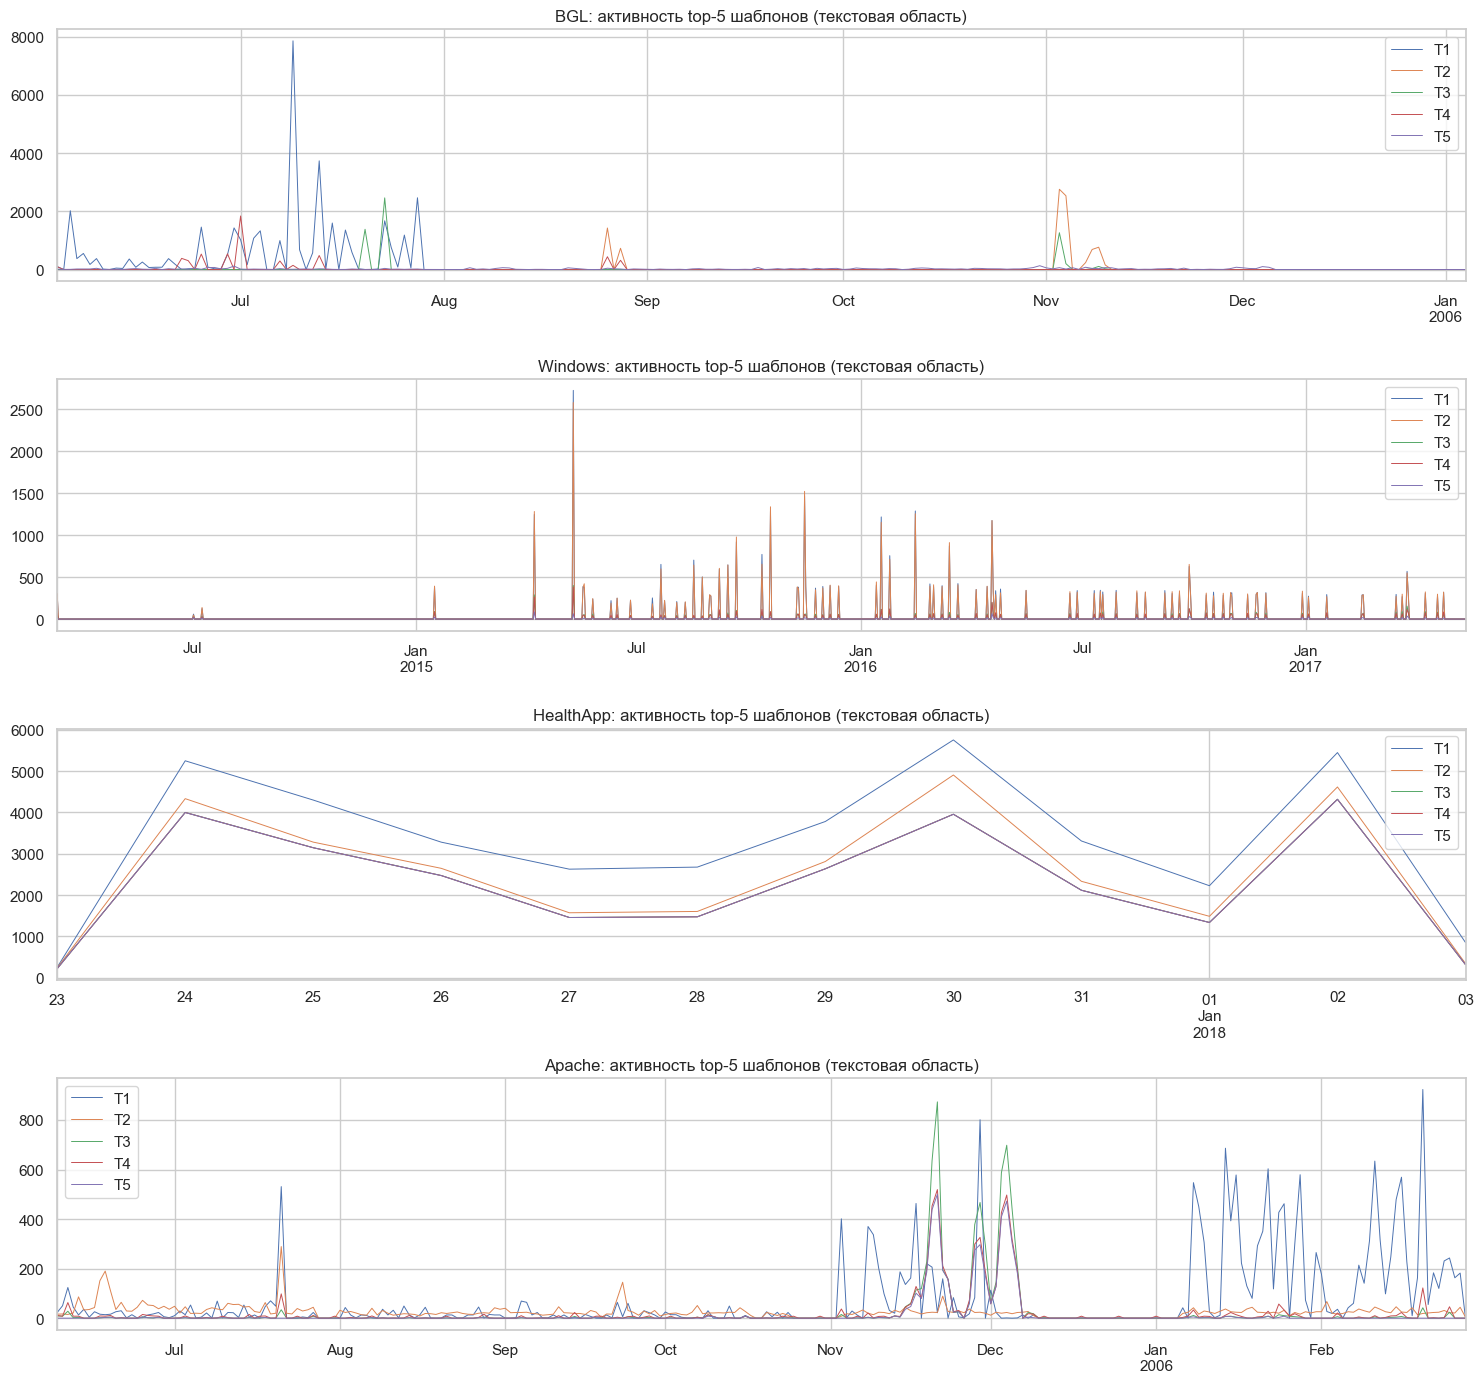

In [10]:
template_stats = {}
fig, axes = plt.subplots(4, 1, figsize=(15, 14))
for ax, (name, df) in zip(axes, list(datasets.items())):
    df = mine_templates(df)
    datasets[name] = df
    stats = template_lifetimes(df)
    template_stats[name] = stats
    title(name + ": Drain3 (текстовая область)")
    display(pd.DataFrame({"templates": [len(stats)], "singletons": [stats["count"].eq(1).sum()],
                          "top10_share": [stats["count"].head(10).sum() / len(df)]}))
    display(stats.head(10))
    display(stats.sort_values(["count", "first_seen"]).head(10))
    display(stats.sort_values("first_seen").head(5))
    display(stats.sort_values("last_seen").head(5))
    top = stats.head(5).index
    display(pd.DataFrame({"plot_id": ["T" + str(i+1) for i in range(len(top))], "template": top}))
    daily = (df[df.template.isin(top)].dropna(subset=["timestamp"])
             .groupby([pd.Grouper(key="timestamp", freq="1D"), "template"]).size().unstack(fill_value=0))
    daily = daily.reindex(columns=top, fill_value=0)
    daily = daily.reindex(pd.date_range(pd.Timestamp(audits[name]["min_time"]).floor("D"),
                                      pd.Timestamp(audits[name]["max_time"]).floor("D"), freq="D"), fill_value=0)
    daily.columns = ["T" + str(i+1) for i in range(len(daily.columns))]
    daily.plot(ax=ax, lw=.7, title=name + ": активность top-5 шаблонов (текстовая область)")
plt.tight_layout()
plt.show()

## 9. Разметка (если есть)

Только BGL содержит исходную разметку: первое поле **каждой записи** — alert-категория;
`-` означает non-alert. Это не готовая разметка сессии/окна и не доказательство отказа узла.
Для остальных трёх датасетов поля `ERROR`/`WARN` не превращаем в искусственную ground truth.

Полный BGL: концентрация по меткам, уровням, узлам, минутам и часам; длины сообщения заголовка по классу.
«Alert-эпизод» ниже — последовательность занятых алертами минут с разрывом не более 1/5/30 минут.
Длительность зависит от этого определения и не равна документированному времени инцидента.
Шаблоны и распределение полных сообщений по классам — по текстовой выборке.
«Только аномальный/нормальный» шаблон означает только наблюдаемую эксклюзивность в ней.

,records_full,alerts_full,alert_share_full
0,4747963,348460,0.073391


,count,share
-,4399503,9.266085e-01
KERNDTLB,152734,3.216832e-02
KERNSTOR,63491,1.337226e-02
APPSEV,49651,1.045733e-02
KERNMNTF,31531,6.640953e-03
...,...,...
MONNULL,2,4.212333e-07
KERNBIT,1,2.106166e-07
MONILL,1,2.106166e-07
KERNEXT,1,2.106166e-07


,all,alert,alert_rate_within_level,share_among_alerts,share_among_normal
INFO,3735813,0.0,0.000000,0.000000,8.491443e-01
FATAL,855195,348398.0,0.407390,0.999822,1.151941e-01
WARNING,23357,0.0,0.000000,0.000000,5.309009e-03
SEVERE,19213,0.0,0.000000,0.000000,4.367084e-03
ERROR,112355,0.0,0.000000,0.000000,2.553811e-02
Kill,306,0.0,0.000000,0.000000,6.955331e-05
FAILURE,1714,62.0,0.036173,0.000178,3.754970e-04
single,4,0.0,0.000000,0.000000,9.091936e-07
microseconds,4,0.0,0.000000,0.000000,9.091936e-07
"0x00544eb8,",2,0.0,0.000000,0.000000,4.545968e-07


,all,alert,alert_rate
R30-M0-N9-C:J16-U01,152329,152185.0,0.999055
NULL,89296,271.0,0.003035
R00-M0-NC-I:J18-U11,524,169.0,0.322519
R63-M0-L2-U21-A,160,160.0,1.000000
R50-M1-NC-I:J18-U11,411,148.0,0.360097
R00-M0-N0-I:J18-U11,478,131.0,0.274059
R00-M0-N4-I:J18-U01,479,128.0,0.267223
R00-M0-N4-I:J18-U11,524,126.0,0.240458
R00-M0-N0-I:J18-U01,475,126.0,0.265263
R00-M0-N8-I:J18-U01,470,125.0,0.265957


Узлов с хотя бы одним алертом: 31375 из 69252.

,alert,records,mean_header_message_chars
0,False,4399503,49.081846
1,True,348460,45.837499


,alert,records_full,mean_raw_record_chars_without_CRLF,max_raw_record_chars
0,False,4399503,155.180961,928
1,True,348460,159.897495,299


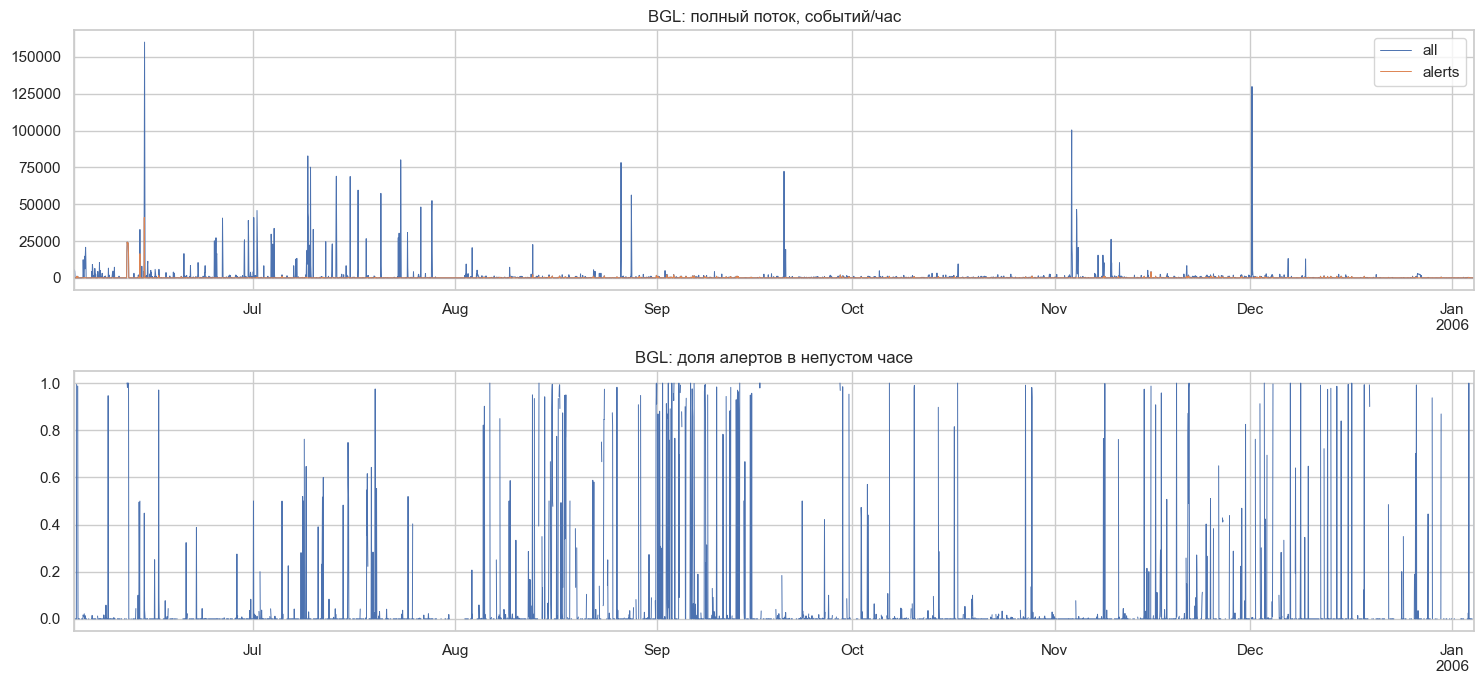

,all_records,alerts,alert_rate
all_records,1.000000,0.269492,0.013370
alerts,0.269492,1.000000,0.283724
alert_rate,0.013370,0.283724,1.000000


### BGL: эпизоды алертов, допустимый разрыв 1 мин

,start,end,alerts,occupied_minutes,span_minutes
minute,,,,,
29,2005-06-11 17:17:00,2005-06-11 23:39:00,152183,383,383.0
40,2005-06-14 09:47:00,2005-06-14 09:56:00,20480,10,10.0
38,2005-06-14 09:05:00,2005-06-14 09:14:00,16384,10,10.0
37,2005-06-13 17:36:00,2005-06-13 17:44:00,16384,9,9.0
41,2005-06-14 10:15:00,2005-06-14 10:17:00,6144,3,3.0
718,2005-11-15 19:18:00,2005-11-15 19:21:00,4096,4,4.0
39,2005-06-14 09:31:00,2005-06-14 09:33:00,4096,3,3.0
42,2005-06-14 11:16:00,2005-06-14 11:17:00,2048,2,2.0
668,2005-10-28 12:59:00,2005-10-28 13:00:00,2048,2,2.0


,span_minutes,alerts
count,902.000000,902.000000
mean,2.037694,386.319290
std,12.791972,5176.478743
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,3.500000
75%,2.000000,144.000000
max,383.000000,152183.000000


Число эпизодов: 902; доля алертов в десяти крупнейших: 64.73%.

### BGL: эпизоды алертов, допустимый разрыв 5 мин

... (9 outputs left out)

### Шаблоны только с алертами в выборке

,normal,alert
template,,
data TLB error interrupt,0,3265
data storage interrupt,0,1348
"ciod: Error reading message prefix on CioStream socket to <IPv4>:<NUM>, <*> <*> <*> <*>",0,634
Lustre mount FAILED : <*> : point <path>,0,522
ciod: Error reading message prefix after <*> on CioStream socket to <IPv4>:<NUM>: <*> <*> <*> <*>,0,517
rts: kernel terminated for reason <NUM>,0,384
"Error receiving packet on tree network, expecting type <NUM> instead of type <NUM> <*> <*> <NUM> <NUM>) <*> PSR1=<NUM> PRXF=<NUM> PIXF=<NUM>",0,128
Lustre mount FAILED : <*> : block_id : location,0,126
ciod: failed to read message prefix on control stream (CioStream socket to <IPv4>:<NUM>,0,124


### Шаблоны только с нормальными записями в выборке

,normal,alert
template,,
generating core.<NUM>,36021,0
iar <*> dear <*>,9300,0
<NUM> floating point alignment exceptions,5478,0
<NUM> double-hummer alignment exceptions,5372,0
"CE sym <NUM>, at <HEX>, mask <HEX>",4209,0
"<NUM> total interrupts. <NUM> critical input interrupts. <NUM> microseconds total spent on critical input interrupts, <NUM> microseconds max time in a critical input interrupt.",2878,0
<NUM> microseconds spent in the rbs signal handler during <NUM> calls. <NUM> microseconds was the maximum time for a single instance of a correctable ddr.,2864,0
instruction cache parity error corrected,2220,0
idoproxydb hit ASSERT condition: ASSERT <*> Source <*> Source line=<NUM> Function=int <*> <*>,1780,0


In [11]:
a = audits["BGL"]
normal = a["labels"].get("-", 0)
alerts = a["counts"]["records"] - normal
display(pd.DataFrame({"records_full": [a["counts"]["records"]], "alerts_full": [alerts],
                      "alert_share_full": [alerts / a["counts"]["records"]]}))
show_counter(a["labels"], 50)
level_stats = pd.DataFrame({"all": a["levels"], "alert": a["anomaly_levels"]}).fillna(0)
level_stats["alert_rate_within_level"] = level_stats.alert / level_stats["all"]
level_stats["share_among_alerts"] = level_stats.alert / alerts
level_stats["share_among_normal"] = (level_stats["all"] - level_stats.alert) / normal
display(level_stats)
host_stats = pd.DataFrame({"all": a["hosts"], "alert": a["anomaly_hosts"]}).fillna(0)
host_stats["alert_rate"] = host_stats.alert / host_stats["all"]
display(host_stats.sort_values("alert", ascending=False).head(15))
display(Markdown(f"Узлов с хотя бы одним алертом: {int(host_stats.alert.gt(0).sum())} из {len(host_stats)}."))
length_classes = []
for label, counter in a["length_by_label"].items():
    n = sum(counter.values())
    length_classes.append({"alert": label, "records": n, "mean_header_message_chars": sum(k*v for k,v in counter.items()) / n})
display(pd.DataFrame(length_classes))
record_lengths = []
for label, counter in a["record_length_by_label"].items():
    n = sum(counter.values())
    record_lengths.append({"alert": label, "records_full": n,
                           "mean_raw_record_chars_without_CRLF": sum(k*v for k,v in counter.items()) / n,
                           "max_raw_record_chars": max(counter)})
display(pd.DataFrame(record_lengths))
hourly_all, hourly_alert = window_counts(a, "1h"), window_counts(a, "1h", anomaly=True)
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
pd.DataFrame({"all": hourly_all, "alerts": hourly_alert}).plot(ax=axes[0], lw=.7, title="BGL: полный поток, событий/час")
(hourly_alert / hourly_all.replace(0, np.nan)).plot(ax=axes[1], lw=.7, title="BGL: доля алертов в непустом часе")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"all_records": hourly_all, "alerts": hourly_alert,
                      "alert_rate": hourly_alert / hourly_all.replace(0, np.nan)}).corr())
for gap in [1, 5, 30]:
    episodes = anomaly_episodes(a, gap)
    title(f"BGL: эпизоды алертов, допустимый разрыв {gap} мин")
    display(episodes.head(10))
    display(episodes[["span_minutes", "alerts"]].describe())
    display(Markdown(f"Число эпизодов: {len(episodes)}; доля алертов в десяти крупнейших: {episodes.alerts.head(10).sum()/alerts:.2%}."))
bgl = datasets["BGL"]
display(bgl.assign(message_length=bgl.message.str.len()).groupby("is_anomaly").message_length.describe())
display(pd.crosstab(bgl.component, bgl.is_anomaly, normalize="columns").rename(columns={False: "normal_share", True: "alert_share"}))
template_labels = pd.crosstab(bgl.template, bgl.is_anomaly).reindex(columns=[False, True], fill_value=0)
template_labels.columns = ["normal", "alert"]
title("Шаблоны только с алертами в выборке")
display(template_labels[(template_labels.normal == 0) & (template_labels.alert > 0)].sort_values("alert", ascending=False).head(15))
title("Шаблоны только с нормальными записями в выборке")
display(template_labels[(template_labels.alert == 0) & (template_labels.normal > 0)].sort_values("normal", ascending=False).head(15))

### Читаем десять алертов BGL

Ниже первые десять записей с исходным alert-лейблом — это соседние записи одного локального всплеска,
поэтому они не представляют всё разнообразие аномалий. Дополнительно выводим по одному случайному примеру
из десяти разных alert-категорий, присутствующих в текстовой выборке.
Для каждого примера интерпретируем наличие ошибок/сбоев в тексте; окончательная верификация отказа
требует внешних данных. Даже нормальная запись может содержать слово `error` (например, corrected error).

In [12]:
examples = pd.DataFrame(audits["BGL"]["anomalies"])
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(examples[["line_no", "raw_timestamp", "label", "level", "host", "message"]])
    diverse = (bgl[bgl.is_anomaly].groupby("label", group_keys=False)
               .sample(n=1, random_state=SEED).head(10))
    display(diverse[["line_no", "timestamp", "label", "level", "message"]])
    display(bgl.loc[~bgl.is_anomaly & bgl.message.str.contains("error", case=False),
                    ["line_no", "timestamp", "label", "message"]].head(5))

,line_no,raw_timestamp,label,level,host,message
0,14738,2005-06-04-00.24.32.398284,APPREAD,FATAL,R23-M1-N8-I:J18-U11,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33399
1,14739,2005-06-04-00.24.32.432192,APPREAD,FATAL,R04-M1-N4-I:J18-U11,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33569
2,14740,2005-06-04-00.24.32.481570,APPREAD,FATAL,R04-M1-N4-I:J18-U01,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33570
3,14741,2005-06-04-00.24.33.168659,APPREAD,FATAL,R35-M1-N0-I:J18-U11,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33459
4,14742,2005-06-04-00.24.33.203068,APPREAD,FATAL,R35-M1-N0-I:J18-U01,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33460
5,14743,2005-06-04-00.24.33.236793,APPREAD,FATAL,R36-M0-N8-I:J18-U11,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33231
6,14744,2005-06-04-00.24.33.270584,APPREAD,FATAL,R36-M0-N8-I:J18-U01,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33232
7,14745,2005-06-04-00.24.33.304903,APPREAD,FATAL,R36-M0-NC-I:J18-U11,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33229
8,14746,2005-06-04-00.24.33.352044,APPREAD,FATAL,R36-M0-NC-I:J18-U01,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33230
9,14747,2005-06-04-00.24.33.385805,APPREAD,FATAL,R36-M0-N0-I:J18-U11,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:33235


,line_no,timestamp,label,level,message
18615,886824,2005-06-22 09:25:29.504732,APPALLOC,FATAL,ciod: Error creating node map from file /p/gb2/draeger/benchmark/dat16k_062205/map16k_bipartyz: Cannot allocate memory
33176,1580304,2005-07-09 04:33:59.293390,APPBUSY,FATAL,ciod: Error creating node map from file /p/gb2/pakin1/sweep3d-5x5x400-10mk-3mmi-1024pes-sweep/sweep.map: Device or resource busy
18283,871127,2005-06-20 19:04:13.704164,APPCHILD,FATAL,ciod: Error creating node map from file /p/gb2/cabot/miranda/newmaps/8k_128x64x1_8x4x4.map: No child processes
98436,4673600,2005-12-11 19:19:21.972057,APPOUT,FATAL,ciod: LOGIN chdir(/p/gb1/stella/RAPTOR/2183) failed: Input/output error
17307,826270,2005-06-16 14:50:43.908919,APPREAD,FATAL,ciod: failed to read message prefix on control stream (CioStream socket to 172.16.96.116:50031
89621,4258905,2005-11-21 14:55:48.503590,APPRES,FATAL,"ciod: Error reading message prefix on CioStream socket to 172.16.96.116:41411, Connection reset by peer"
70834,3368317,2005-09-11 03:22:39.214392,APPSEV,FATAL,ciod: Error reading message prefix after LOAD_MESSAGE on CioStream socket to 172.16.96.116:45825: Link has been severed
89633,4259403,2005-11-21 14:59:55.747989,APPTO,FATAL,"ciod: Error reading message prefix on CioStream socket to 172.16.96.116:43460, Connection timed out"
31675,1510725,2005-07-05 12:29:00.819478,APPUNAV,FATAL,ciod: Error creating node map from file /home/auselton/bgl/64mps.sequential.mapfile: Resource temporarily unavailable
6113,293267,2005-06-11 20:13:27.109279,KERNDTLB,FATAL,data TLB error interrupt


,line_no,timestamp,label,message
0,75,2005-06-03 15:43:01.470239,-,instruction cache parity error corrected
1,121,2005-06-03 15:43:14.548730,-,instruction cache parity error corrected
2,203,2005-06-03 15:43:43.723907,-,instruction cache parity error corrected
3,247,2005-06-03 15:43:59.589104,-,instruction cache parity error corrected
4,251,2005-06-03 15:44:00.184283,-,instruction cache parity error corrected


Первые десять алертов описывают `failed to read message prefix on control stream` с адресом CioStream:
текст согласуется с alert-категорией, но десять похожих строк не означают десять независимых инцидентов.
Нормальные `instruction cache parity error corrected` показывают, почему поиск слова `error` не заменяет лейбл.
В разнообразных примерах APPALLOC связан с невозможностью выделить память, APPTO — с таймаутом,
APPRES — со сбросом соединения, KERNDTLB — с TLB error interrupt: тексты согласуются с категориями алертов.
APPBUSY/APPUNAV могут описывать временную недоступность ресурса, а не длительный отказ системы.
На следующих шагах важно разделять рядовые восстановленные ошибки, alert-события и подтверждённые отказы;
коррелирующие строки одного эпизода нельзя случайно разнести между train/test.

## 10. Временные окна

Сравниваем неперекрывающиеся окна 1/5/15/60 минут на полной оси min–max. Событие на правой границе
попадает в следующее окно (`resample` с левой границей); интервалы вне наблюдаемого диапазона не добавляются.
Первые/последние окна могут быть неполными. «Концентрированное» окно — выше Q3+1.5×IQR непустых окон
(эвристика); также выводим p99 и максимум. Нулевые окна не объявляем нормой или простоем.
Для BGL отдельно считаем окна с хотя бы одним алертом; это **производная**, не исходная разметка.

In [13]:
window_rows = []
for name, a in audits.items():
    for rule in ["1min", "5min", "15min", "60min"]:
        counts = window_counts(a, rule)
        nonzero = counts[counts > 0]
        q1, q3 = nonzero.quantile([.25, .75])
        threshold = q3 + 1.5 * (q3 - q1)
        row = {"dataset": name, "rule": rule, "windows": len(counts), "empty": int(counts.eq(0).sum()),
               "empty_share": counts.eq(0).mean(), "p99": counts.quantile(.99), "max": counts.max(),
               "concentration_threshold": threshold, "concentrated": int(counts.gt(threshold).sum())}
        if name == "BGL":
            row["windows_with_alert"] = int(window_counts(a, rule, anomaly=True).gt(0).sum())
        window_rows.append(row)
    title(name + ": пять самых плотных 5-минутных окон")
    display(window_counts(a, "5min").nlargest(5).rename("records").to_frame())
window_summary = pd.DataFrame(window_rows)
display(window_summary)

### BGL: пять самых плотных 5-минутных окон

,records
2005-09-20 12:05:00,42272
2005-12-01 06:35:00,39405
2005-12-01 08:35:00,38668
2005-12-01 06:40:00,35433
2005-12-01 08:30:00,32814


### Windows: пять самых плотных 5-минутных окон

,records
2015-11-16 03:15:00,1807408
2015-09-21 03:00:00,1634450
2015-10-19 03:05:00,1287383
2016-03-01 03:00:00,1181693
2016-03-08 03:00:00,1181215


### HealthApp: пять самых плотных 5-минутных окон

,records
2017-12-29 12:25:00,3297
2017-12-30 18:15:00,3102
2017-12-30 22:20:00,3100
2018-01-02 19:00:00,2857
2017-12-24 18:50:00,2757


### Apache: пять самых плотных 5-минутных окон

,records
2005-07-21 03:35:00,1358
2006-01-25 01:20:00,514
2006-01-22 21:45:00,475
2005-11-03 16:15:00,436
2005-11-17 12:30:00,432


,dataset,rule,windows,empty,empty_share,p99,max,concentration_threshold,concentrated,windows_with_alert
0,BGL,1min,309139,281469,0.910493,316.00,16409,101.000,4866,1838.0
1,BGL,5min,61829,47335,0.765579,1486.76,42272,107.000,2649,1054.0
2,BGL,15min,20611,11989,0.581680,5523.10,103213,203.000,1478,862.0
3,BGL,60min,5154,1536,0.298021,23755.84,160082,799.000,539,665.0
4,Windows,1min,1666131,1660428,0.000000,0.00,1048512,2050.000,1139,NaN
5,Windows,5min,333227,330450,0.991666,0.00,1807408,2046.500,372,NaN
6,Windows,15min,111076,108830,0.979780,840.00,2849888,2036.000,194,NaN
7,Windows,60min,27770,25824,0.929924,921.00,3786210,1902.500,133,NaN
8,HealthApp,1min,15105,8108,0.536776,425.96,990,46.000,890,NaN
9,HealthApp,5min,3021,723,0.239325,1539.00,3297,162.000,296,NaN


## 11. Вывод

Численные результаты предыдущих разделов сводим в таблицу. Финальный Markdown-дайджест фиксирует выводы
проверенного запуска при указанных параметрах. После изменения данных, парсинга или размера выборки
нужно повторить расчёты и актуализировать этот текст по новой сводке.

In [14]:
summary_rows = []
for name, a in audits.items():
    df, stats = datasets[name], template_stats[name]
    windows = window_counts(a, "5min")
    summary_rows.append({"dataset": name, "physical_lines_full": a["counts"]["physical_lines"],
                         "logical_records_full": a["counts"]["records"], "text_records": len(df),
                         "span_days": (a["max_time"]-a["min_time"]).total_seconds()/86400,
                         "backward_steps_full": a["counts"].get("backward_steps", 0),
                         "drain_templates_text_scope": len(stats),
                         "top10_template_share": stats["count"].head(10).sum()/len(df),
                         "empty_5min_share_full": windows.eq(0).mean()})
summary = pd.DataFrame(summary_rows).set_index("dataset")
display(summary)
summary.to_json(ROOT / "data/processed/eda_summary.json", orient="index", indent=2)
pd.DataFrame(text_summaries).to_json(ROOT / "data/processed/eda_message_stats.json", orient="records", indent=2)
pd.DataFrame(entity_rows).to_json(ROOT / "data/processed/eda_entities.json", orient="records", indent=2)

,physical_lines_full,logical_records_full,text_records,span_days,backward_steps_full,drain_templates_text_scope,top10_template_share,empty_5min_share_full
dataset,,,,,,,,
BGL,4747963,4747963,100000,214.678644,0,312,0.733870,0.765579
Windows,114608388,114422303,100000,1157.034664,5,102,0.967010,0.991666
HealthApp,253395,253395,253395,10.488547,59,202,0.877133,0.239325
Apache,56482,52004,52004,263.904132,190,133,0.963945,0.909374


### Дайджест и открытые вопросы

**Наблюдения по полным файлам:**

- **BGL:** 4,747,963 физических строк → 4,747,963 записей с заголовком; 0 строк без заголовка. Наблюдаемый диапазон 2005-06-03 15:42:50.363779 — 2006-01-04 08:00:05.233639; 0 возвратов времени.
- **Windows:** 114,608,388 физических строк → 114,422,303 записей с заголовком; 186,085 строк без заголовка. Наблюдаемый диапазон 2014-03-12 20:34:42 — 2017-05-12 21:24:37; 5 возвратов времени.
- **HealthApp:** 253,395 физических строк → 253,395 записей с заголовком; 0 строк без заголовка. Наблюдаемый диапазон 2017-12-23 22:15:29.606000 — 2018-01-03 09:59:00.095000; 59 возвратов времени.
- **Apache:** 56,482 физических строк → 52,004 записей с заголовком; 4,478 строк без заголовка. Наблюдаемый диапазон 2005-06-09 06:07:04 — 2006-02-28 03:49:01; 190 возвратов времени.

**Качество и время.** В BGL сохранены 34,470 записей с пустым сообщением, которые прежний парсер терял. HealthApp требует дат yyyyMd и целых миллисекунд без ведущих нулей; после исправления разобраны все 253 395 временных меток. В BGL есть 4 строки с NUL внутри сообщения, в HealthApp — 1 строка с NUL-префиксом. В Apache 56 481 перевод строки и ещё одна непустая последняя строка без LF: поэтому физический счётчик отличается на единицу от опубликованной таблицы. Apache хранит много текста без заголовков: семантику автоматического присоединения к предыдущей записи надо подтвердить.

В полном BGL найдено 4 точных байтовых повтора записи сверх первого вхождения.

**Два определения охвата Windows.** Разность последней и первой записи в порядке файла — 226,704 дня; хронологический max–min — 1157,035 дня. Первый показатель практически совпадает с опубликованными 226+ днями, но не описывает весь диапазон дат. По полному потоку: 2014 — 1 685 153 записи, 2015 — 50 831 314, 2016 — 50 525 765, 2017 — 11 380 071. Старые даты встречаются в больших блоках; история объединения исходных файлов нужна для объяснения их порядка и проверки полноты.

**Объёмы, продуценты и дрейф.** BGL: крупнейший компонент RAS/KERNEL (91.1% записей); Windows: крупнейший компонент CBS (99.9% записей); HealthApp: крупнейший компонент Step_LSC (32.1% записей). Поля хоста есть только в BGL; компоненты не доказывают микросервисную архитектуру. Средние по часам суток показывают различия активности, но короткий HealthApp и неполные периоды не позволяют уверенно утверждать сезонность.

**Сообщения.** Медиана / p99 длины в символах (в текстовой области): BGL — 26 / 180; Windows — 193 / 330; HealthApp — 44 / 82; Apache — 63 / 133. Распределения слов, биграмм, целостных сообщений и классов символов приведены в разделе 6. Редкие и длинные сообщения требуют чтения; сами по себе эти свойства не подтверждают инцидент.

**Сущности.** В текстовой области найдено уникальных значений (IPv4/UUID/session-кандидаты по синтаксису): BGL — 383/0/0; Windows — 30/6/368; HealthApp — 1/0/0; Apache — 4696/0/0. Пути, URL, порты, кандидаты в хэши и устройства подсчитаны отдельно в разделе 7. Форматный кандидат не доказывает назначение ID; thread ID не подменяет session ID.

**Текст и шаблоны.** Apache/HealthApp изучены полностью; BGL/Windows — на равномерной выборке 100 000 целых записей. BGL: 312 Drain3-шаблонов, top-10 покрывают 73.4% текстовой области; Windows: 102 Drain3-шаблонов, top-10 покрывают 96.7% текстовой области; HealthApp: 202 Drain3-шаблонов, top-10 покрывают 87.7% текстовой области; Apache: 133 Drain3-шаблонов, top-10 покрывают 96.4% текстовой области. Эти количества несопоставимы с числом шаблонов полных BGL/Windows. Редкость, эксклюзивность шаблона и его первая/последняя дата в выборке не доказывают те же свойства в полном потоке.

**Разметка.** Только BGL размечен: 348,460 alert-записей из 4,747,963 (7.339%). При допустимом разрыве 5 минут получено 816 операционных alert-эпизодов; десять крупнейших содержат 64.8% алертов. Соседние APPREAD-сообщения согласуются с ошибкой чтения CioStream, а нормальные corrected parity errors показывают, что слово error не заменяет лейбл. Повторения ошибок и их группировка не доказывают независимые отказы.

**Временные окна.** Доля пустых пятиминутных окон по полной оси: BGL — 76.6%; Windows — 99.2%; HealthApp — 23.9%; Apache — 90.9%. Нули нельзя объяснять только простоем: неизвестны политика логирования, ротация и потери сбора. Размер окна меняет долю нулей и плотность всплесков, поэтому его выбирают по целевой задержке детекции и проверяют на train-периоде.

**Что использовать дальше.** Частоты шаблонов, объём потока, доли уровней/компонентов, длины сообщений и временные признаки — кандидаты для моделей, а не уже доказанные предикторы. Сохранять исходный текст и номера строк. Разделять данные по времени с контролем целых alert-эпизодов; Drain3 и словари обучать на train. Для BGL учитывать дисбаланс классов; для остальных датасетов нужна независимая оценка качества без подмены ground truth уровнем ERROR.

**Открытые вопросы:**

- Каковы реальные таймзоны, синхронизация часов и причины несовпадений внешнего/внутреннего времени Windows и Unix/text BGL?
- Как объясняется расхождение наблюдаемого min–max Windows с 226+ днями в описании источника: склейкой архивов, разными периодами сбора или иным определением охвата?
- Строки Apache без времени — продолжения, отдельные события или следы обработки? Есть ли журнал ротации и телеметрия для атрибуции пробелов?
- Какие найденные session/activity/correlation ID действительно связывают транзакции, где они переиспользуются, и можно ли восстановить границы сессий?
- Сколько точных дублей в полном Windows и редких сущностей/шаблонов в полных BGL/Windows? Эти текстовые свойства изучены на выборке; для полной оценки нужен отдельный потоковый или дисковый проход.
- Насколько месячный дрейф категорий связан с изменением нагрузки/версий, а не с составом склеенных файлов? Где маски Drain3 скрывают полезные коды ошибок?
- Какие alert-эпизоды соответствуют реальным отказам и какие полезные признаки сохранят качество на следующем временном периоде?
- Как результаты HPC/Windows/мобильного приложения/HTTP-сервера переносятся на целевые облачные системы? Для проверки переноса нужны логи целевого сервиса.